In [28]:
import numpy as np
import torch

optimizers = {
    "Adadelta": torch.optim.Adadelta,
    "Adafactor": torch.optim.Adafactor,
    "Adagrad": torch.optim.Adagrad,
    "Adam": torch.optim.Adam,
    "AdamW": torch.optim.AdamW,
    "Adamax": torch.optim.Adamax,
    "ASGD": torch.optim.ASGD,
    "LBFGS": torch.optim.LBFGS,
    "NAdam": torch.optim.NAdam,
    "RAdam": torch.optim.RAdam,
    "RMSprop": torch.optim.RMSprop,
    "SGD": torch.optim.SGD,
    "Rprop": torch.optim.Rprop,
}

tensor = torch.tensor([10.0, 10.0], requires_grad=True)
epochs = 1000
graphics = {}

for name, optimizer in optimizers.items():

    opt = optimizer([tensor], lr=1e-1)

    trajectory = []

    # В функции чтобы LBFGS работал
    def closure():
        opt.zero_grad()
        loss = torch.sin(tensor[0]) * torch.cos(tensor[1])
        loss.backward()
        return loss

    for _ in range(epochs):
        opt.step(closure)
        trajectory.append(tensor.detach().numpy().copy())

    trajectory = np.array(trajectory)
    graphics[name] = trajectory

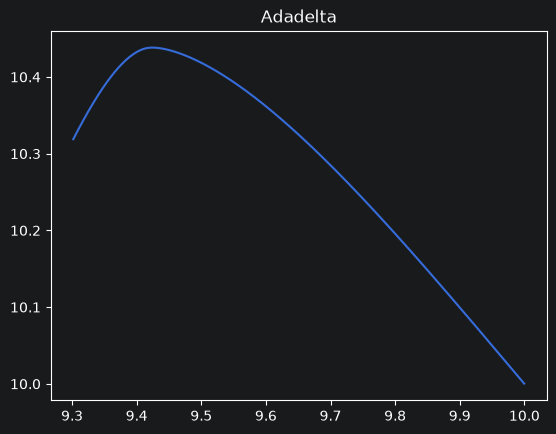

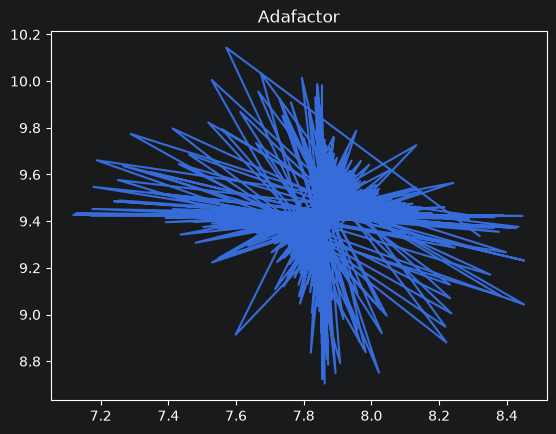

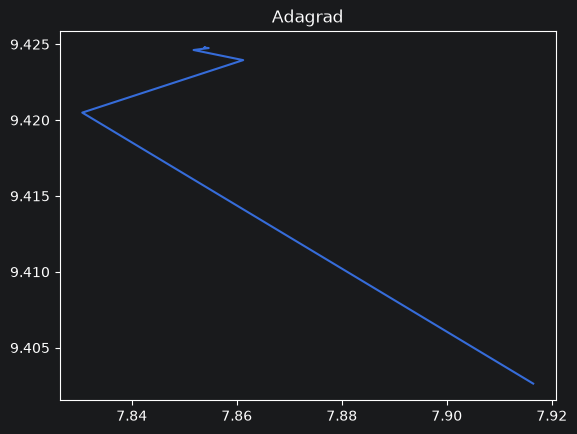

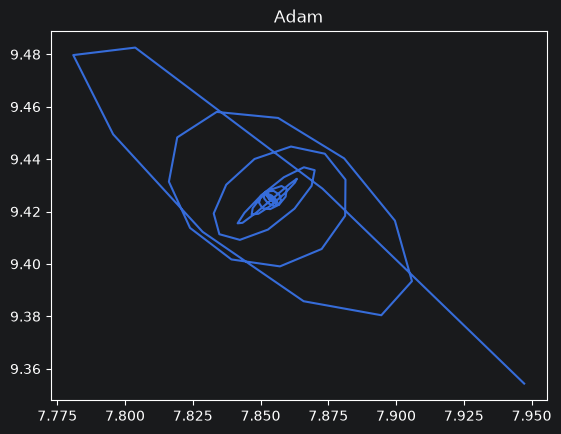

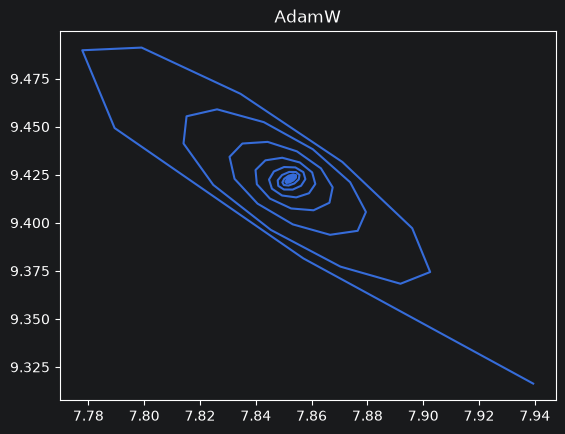

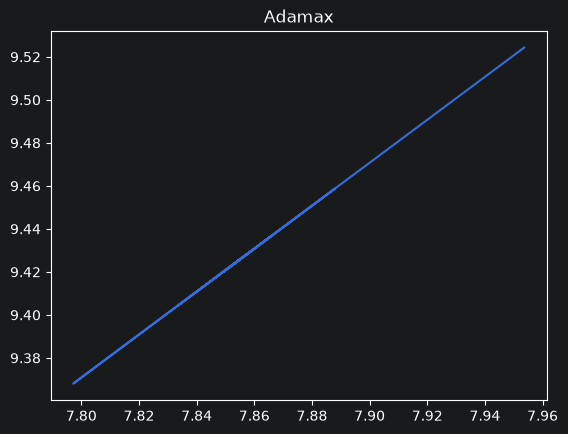

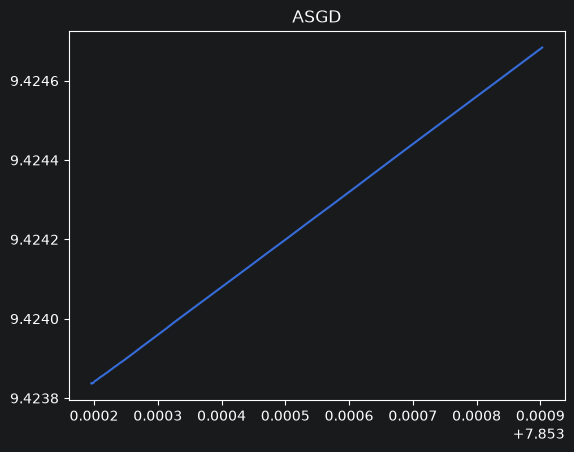

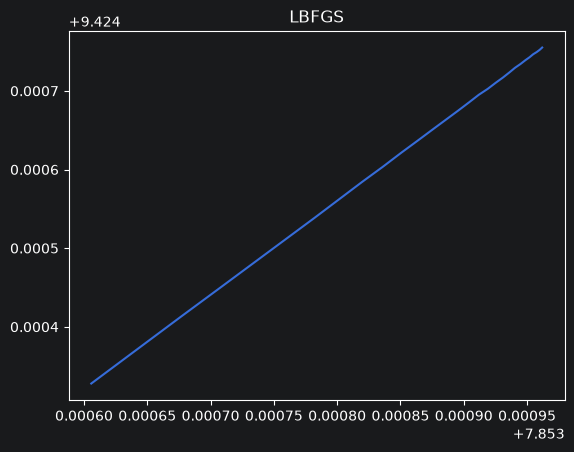

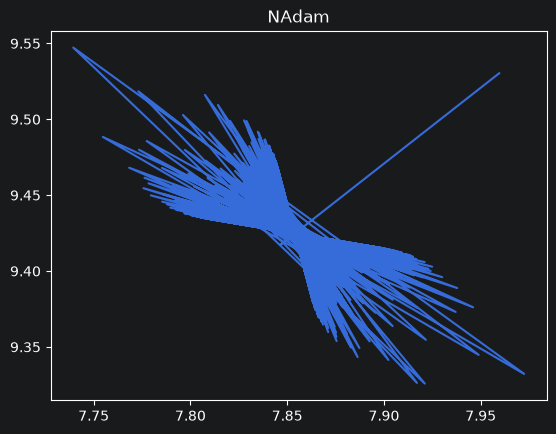

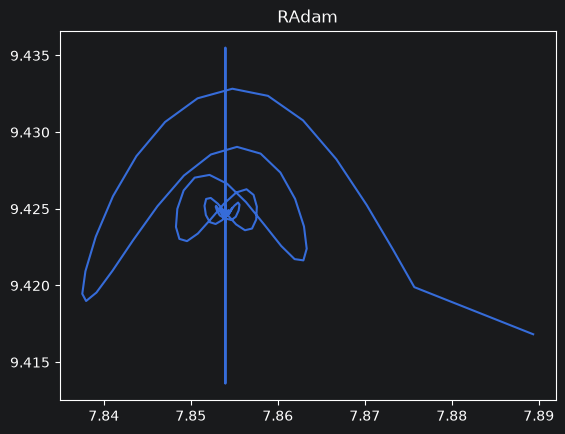

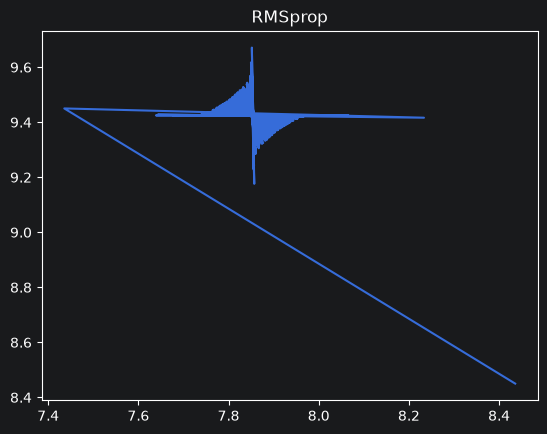

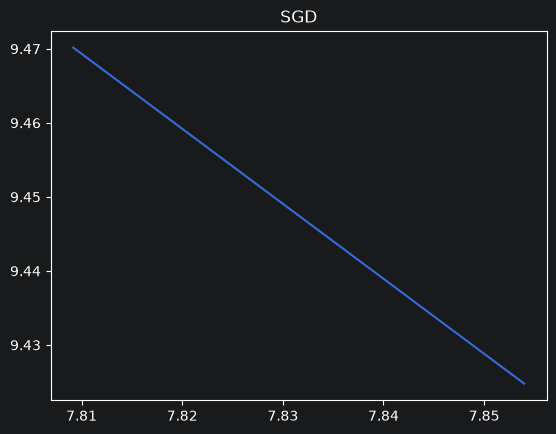

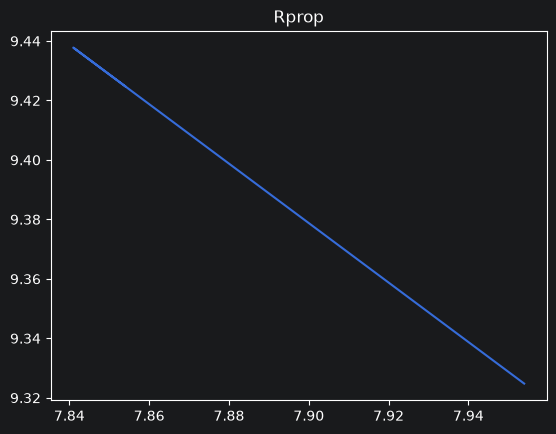

In [29]:
import matplotlib.pyplot as plt

for name, trajectory in graphics.items():
    plt.plot(trajectory[:, 0], trajectory[:, 1])
    plt.title(name)
    plt.show()